# DB-scan 


In [28]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score


sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [29]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4384 entries, 0 to 4383
Data columns (total 36 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   subject_id                         4384 non-null   int64  
 1   ACS_acute_ischemic                 4384 non-null   int64  
 2   Chronic_ischemic                   4384 non-null   int64  
 3   Heart_failure                      4384 non-null   int64  
 4   Valvular_nonrheumatic              4384 non-null   int64  
 5   Myocarditis_or_cardiomyopathy      4384 non-null   int64  
 6   Pericardial_disease                4384 non-null   int64  
 7   Endocarditis                       4384 non-null   int64  
 8   Cardiac_arrest                     4384 non-null   int64  
 9   Arrhythmias_or_conduction          4384 non-null   int64  
 10  number_of_hadm                     4384 non-null   int64  
 11  gender                             4384 non-null   int64

In [30]:
#correletion
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

#print the feautures with correlation higer than 0.7
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

## some consideration
### we drop unique antibitique count

In [31]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identifica colonne categoriche da escludere
categorical_cols = ['subject_id', 'gender'
                    , 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction'
                   ]

# Seleziona solo le colonne numeriche per il clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verifica le colonne numeriche selezionate
print("Colonne numeriche per clustering:")
print(numeric_cols)
print(f"\nNumero di features: {len(numeric_cols)}")


Colonne numeriche per clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Numero di features: 24


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)



In [33]:
#compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean') #pair wise distance
print (dist)
dist = squareform(dist) #distance matrix given the vector dist
print()
print(dist)

[6.45144199 5.90121012 6.13817271 ... 1.05972288 1.48361204 2.54333492]

[[0.         6.45144199 5.90121012 ... 7.50184829 7.66474758 7.52277684]
 [6.45144199 0.         6.74401137 ... 5.25870251 5.36441653 5.46397811]
 [5.90121012 6.74401137 0.         ... 7.68679691 7.75950123 7.82866217]
 ...
 [7.50184829 5.25870251 7.68679691 ... 0.         1.05972288 1.48361204]
 [7.66474758 5.36441653 7.75950123 ... 1.05972288 0.         2.54333492]
 [7.52277684 5.46397811 7.82866217 ... 1.48361204 2.54333492 0.        ]]


## strategia 
### dopo varie prove  vedendo che già con k bassi il numero di cluster è basso , partiamo da k=4

In [34]:
#metodo grafico per stimare EPS
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
profile_df["cluster"]=0

profile_df=profile_df.drop('cluster', axis=1)
def getSortedList (k,dist):
    kth_distances = list()
    for d in dist:
        index_kth_distance = np.argsort(d)[k]
        #ordini la riga aka la lista di distanze da uno specifico punto e prendi la distanza del k-esimo punto più vicino
        kth_distances.append(d[index_kth_distance])
    return sorted(kth_distances)

dist = pdist(X, 'euclidean') #pair wise distance
dist = squareform(dist) #distance matrix given the vector dist
#la matrice risultante contiene alla posizione v_a,b la distanza euclidea tra il punto a e b.
sorted_48=getSortedList(48,dist)
sorted_25 = getSortedList(25,dist)
sorted_10 = getSortedList(10,dist)
sorted_5 = getSortedList(5,dist)
sorted_100 = getSortedList(100,dist)

### step 1: choice of min sample and eps using the silhoutte 
we try 4 differente min sample . We started with low parameters values of min sample and then we use the rule of n+1 and 2*n where n is the numbere of feature we use . The optimal $\varepsilon$ (epsilon) value was estimated using the Elbow Method applied to the k-distance graph . 

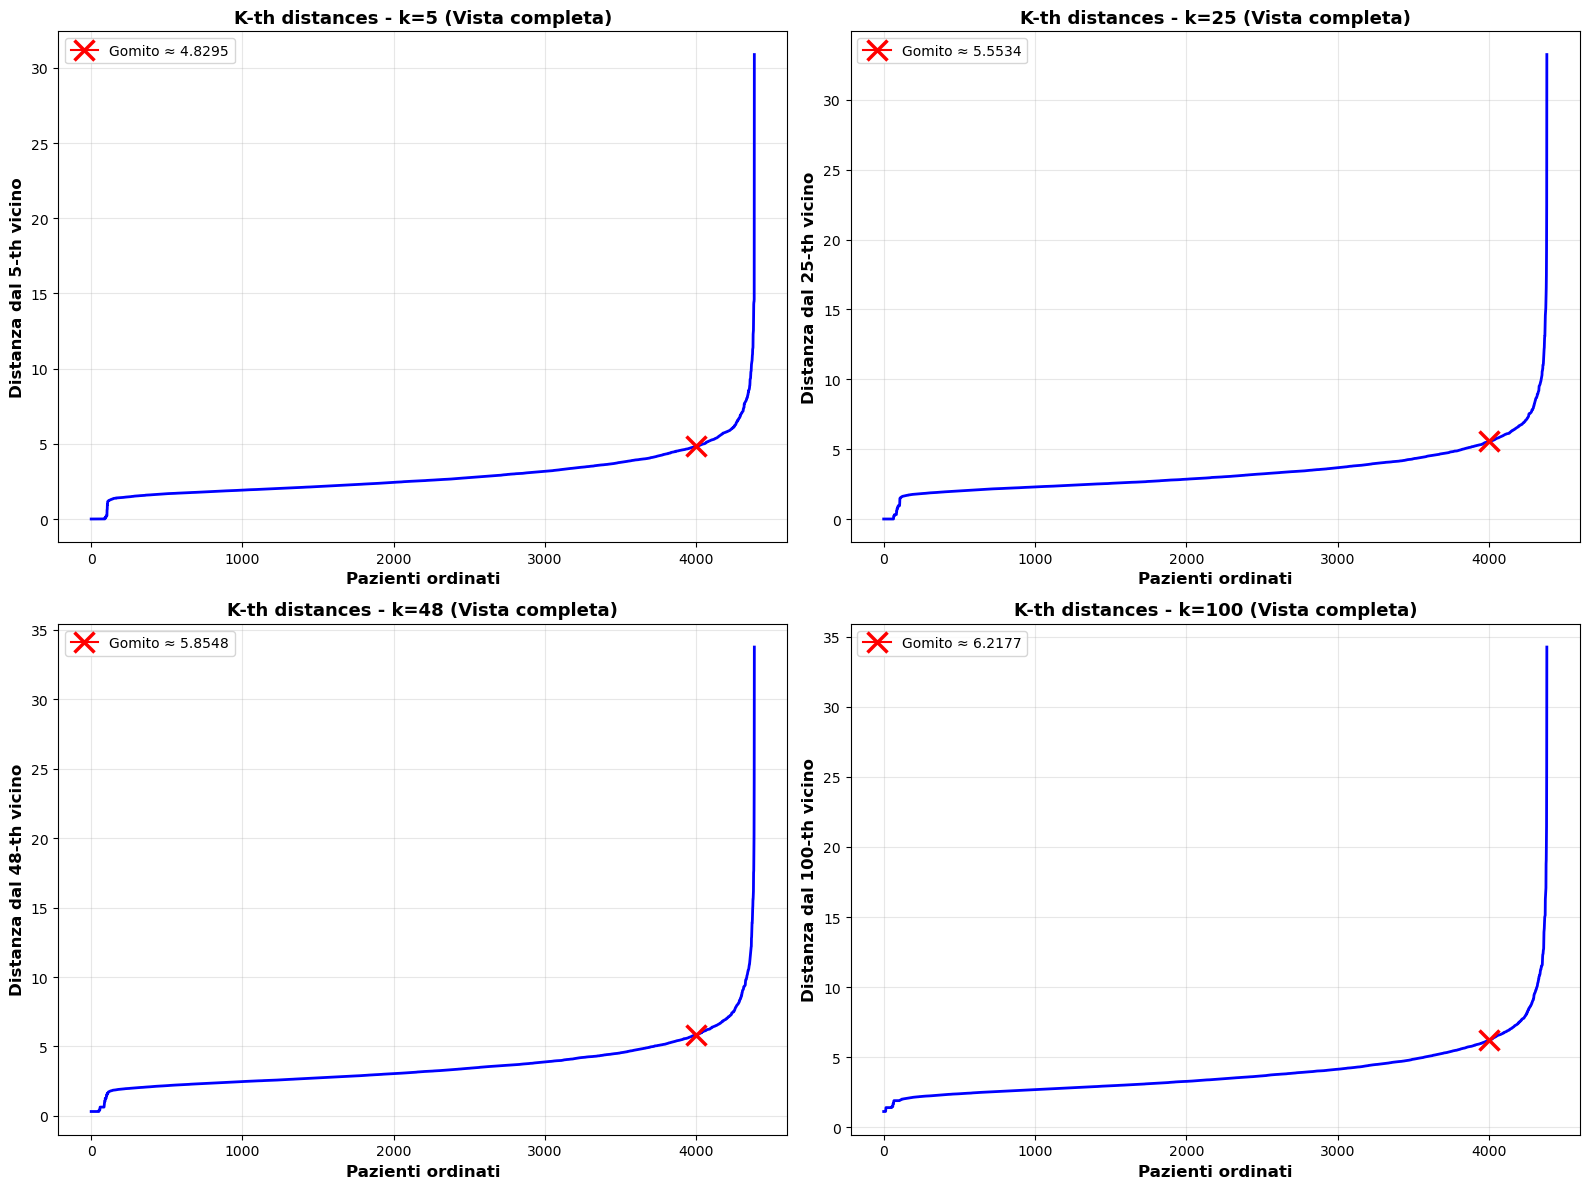


ANALISI EPS PER DIVERSI K (con Silhouette Score)
k= 5 -> EPS ≈ 4.8295 | Clusters: 1 | Noise: 260 | Silhouette: 0.4658
k=25 -> EPS ≈ 5.5534 | Clusters: 1 | Noise: 170 | Silhouette: 0.5137
k=48 -> EPS ≈ 5.8548 | Clusters: 1 | Noise: 141 | Silhouette: 0.5344
k=100 -> EPS ≈ 6.2177 | Clusters: 1 | Noise: 122 | Silhouette: 0.5502


In [35]:

# Metodo Grafico per Stimare EPS - Approccio Interattivo
# Calcola k-th distances per diversi valori di k
k_values = [5, 25, 48,100]
sorted_dists = {}

for k in k_values:
    sorted_dists[k] = getSortedList(k, dist)

# Visualizza i grafici per diversi k
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, k in enumerate(k_values):
    sorted_k = sorted_dists[k]
    
    # Grafico completo
    axes[idx].plot(range(0, len(sorted_k)), sorted_k, linewidth=2, color='blue')
    axes[idx].set_ylabel(f'Distanza dal {k}-th vicino', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Pazienti ordinati', fontsize=12, fontweight='bold')
    axes[idx].set_title(f'K-th distances - k={k} (Vista completa)', fontsize=13, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)
    
    # Evidenzia il gomito all'elemento 4000
    gomito_idx = 4000
    axes[idx].plot(gomito_idx, sorted_k[gomito_idx], marker="x", c="red", ms=15, mew=2.5, label=f'Gomito ≈ {sorted_k[gomito_idx]:.4f}')
    axes[idx].legend(fontsize=10)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ANALISI EPS PER DIVERSI K (con Silhouette Score)")
print("="*60)
for k in k_values:
    gomito_idx = 4000
    eps_suggerito = sorted_dists[k][gomito_idx]
    
    # Calcola DBSCAN con i parametri suggeriti
    dbscan_test = DBSCAN(eps=eps_suggerito, min_samples=k)
    labels_test = dbscan_test.fit_predict(X)
    
    # Conta cluster e noise
    unique_labels = set(labels_test)
    n_clusters_tot = len(unique_labels)
    n_noise = list(labels_test).count(-1) if -1 in labels_test else 0
    n_clusters = n_clusters_tot - (1 if -1 in labels_test else 0)
    
    # Calcola silhouette se ci sono almeno 2 etichette uniche totali
    if n_clusters_tot >= 2 and n_noise < len(labels_test):
        silhouette = silhouette_score(X, labels_test)
        print(f"k={k:2d} -> EPS ≈ {eps_suggerito:.4f} | Clusters: {n_clusters} | Noise: {n_noise} | Silhouette: {silhouette:.4f}")
    else:
        print(f"k={k:2d} -> EPS ≈ {eps_suggerito:.4f} | Clusters: {n_clusters} | Noise: {n_noise} | Silhouette: N/A (tutti noise o 1 cluster)")


While very large values of min_samples were explored for robustness, min_samples = 48 was retained as a reference value, as it aligns with common heuristic recommendations based on the dimensionality of the feature space.

(min_points=48) -> EPS = 5.854781430886453


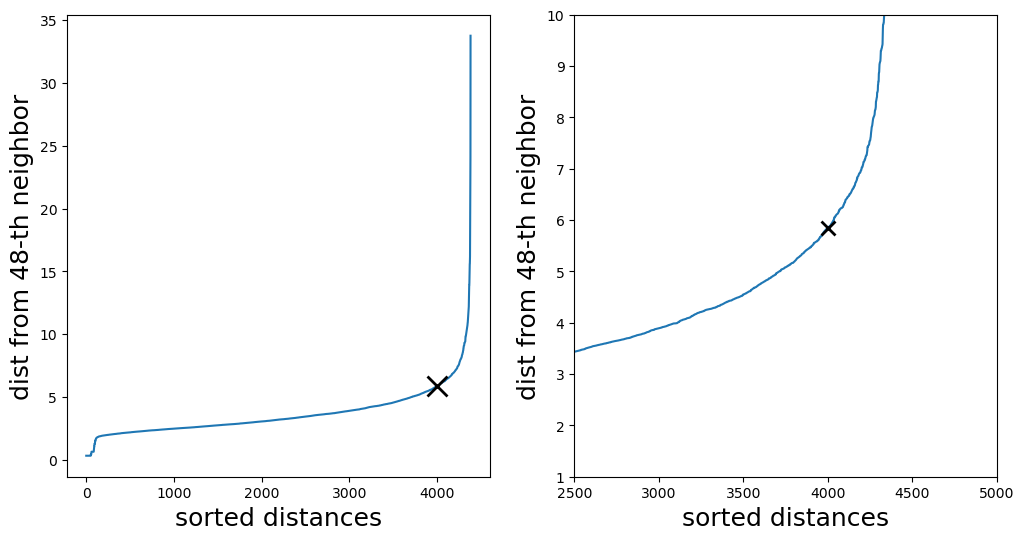

In [36]:
# troviamo il miglior valore di eps
fig,(ax,ax2)= plt.subplots(ncols=2,nrows=1,figsize=(12,6))

ax.plot(range(0, len(sorted_48)), sorted_48)
ax.set_ylabel('dist from 48-th neighbor', fontsize=18)
ax.set_xlabel('sorted distances', fontsize=18)
ax.plot(4000,sorted_48[4000],marker="x",c="black",ms=15,mew=2)

ax2.plot(range(0, len(sorted_48)), sorted_48)
ax2.set_ylabel('dist from 48-th neighbor', fontsize=18)
ax2.set_xlabel('sorted distances', fontsize=18)
ax2.set_ylim(1,10)
ax2.set_xlim(2500,5000)
ax2.plot(4000,sorted_48[4000],marker="x",c="black",ms=10,mew=2)

print("(min_points=48) -> EPS = "+ str(sorted_48[4000]))

### step 2: with the eps found with the elbow method we search a value of min sample with a higher silgoutte 

In [37]:
def print_score(epsList, min_samples_):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples_)
        dbscan.fit(X)
        np.unique(dbscan.labels_, return_counts=True)
        clusters=len(np.unique(dbscan.labels_))
        
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' %(min_samples_,eps,clusters,silhouette_score(X, dbscan.labels_), davies_bouldin_score(X, dbscan.labels_)))

eps1 = sorted_48[4000]
epsList= [eps1]

for i in range(5,151,5):
    print_score(epsList,i)

minsample = 5, eps= 5.854781430886453 => K= 2, Silhouette 0.566481080987143, Davies-Bouldin 2.0048105510961727
minsample = 10, eps= 5.854781430886453 => K= 2, Silhouette 0.5552853775427538, Davies-Bouldin 2.0309214167719167
minsample = 15, eps= 5.854781430886453 => K= 2, Silhouette 0.5492842096712846, Davies-Bouldin 2.040952036568918
minsample = 20, eps= 5.854781430886453 => K= 2, Silhouette 0.5434540805284186, Davies-Bouldin 2.05420751159099
minsample = 25, eps= 5.854781430886453 => K= 2, Silhouette 0.5409665657344594, Davies-Bouldin 2.045675956150015
minsample = 30, eps= 5.854781430886453 => K= 2, Silhouette 0.5376697927239752, Davies-Bouldin 2.0524277943197333
minsample = 35, eps= 5.854781430886453 => K= 2, Silhouette 0.5376697927239752, Davies-Bouldin 2.0524277943197333
minsample = 40, eps= 5.854781430886453 => K= 2, Silhouette 0.5351975634057355, Davies-Bouldin 2.085182315408397
minsample = 45, eps= 5.854781430886453 => K= 2, Silhouette 0.5344096295035616, Davies-Bouldin 2.0870608

A sensitivity analysis was conducted by varying the min_samples parameter from 5 to 150 while keeping the neighborhood radius ε fixed, as determined from the k-distance plot (k = 48). Across the entire range of tested values, DBSCAN consistently identified a single dense cluster accompanied by a limited number of noise points, indicating a highly stable density structure. Internal validation indices, including the Silhouette score, remained relatively stable (≈0.53), reflecting the absence of fragmentation into multiple density-based clusters. As min_samples increased, the gradual reassignment of peripheral observations to noise suggested a smooth decay of density rather than the emergence of distinct subgroups. Based on these observations, min_samples = 48 was retained as a reference value, as it aligns with dimensionality-based heuristics and preserves the observed structural stability under increasingly stringent density constraints.

### step 3 :
found the best min sample we have done a more precisely research of eps

In [38]:

from sklearn.metrics import davies_bouldin_score


for eps_ in np.arange(1,6,0.1):    
    dbscan = DBSCAN(eps=eps_, min_samples=48)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters=len(np.unique(dbscan.labels_))
    print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' %(48,eps_,clusters,silhouette_score(X, dbscan.labels_), davies_bouldin_score(X, dbscan.labels_)))

minsample = 48, eps= 1.0 => K= 2, Silhouette 0.05684963093929589, Davies-Bouldin 0.9136914090833358
minsample = 48, eps= 1.1 => K= 2, Silhouette 0.05684963093929589, Davies-Bouldin 0.9136914090833358
minsample = 48, eps= 1.2000000000000002 => K= 2, Silhouette 0.05843002173266986, Davies-Bouldin 0.9171715898543189
minsample = 48, eps= 1.3000000000000003 => K= 2, Silhouette 0.05843002173266986, Davies-Bouldin 0.9171715898543189
minsample = 48, eps= 1.4000000000000004 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.5000000000000004 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.6000000000000005 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.7000000000000006 => K= 3, Silhouette -0.16107027984195327, Davies-Bouldin 1.8499777172125098
minsample = 48, eps= 1.8000000000000007 => K= 3, Silhouette -0.14045238335593793, Davies-Bouldin 2.0384087084

Varying ε while keeping min_samples = 48 did not reveal stable multi-cluster solutions. For small ε values, DBSCAN produced fragmented and unstable clusters with low or negative Silhouette scores. As ε increased, these fragments progressively merged into a single dominant cluster accompanied by noise, with internal indices stabilizing at higher ε values. This behavior indicates a continuous density structure rather than the presence of multiple well-separated density-based clusters

the final choice is: min sample = 48 eps=5.9 

In [39]:
best_eps=5.9
best_ms=48
dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,5.9
,min_samples,48
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


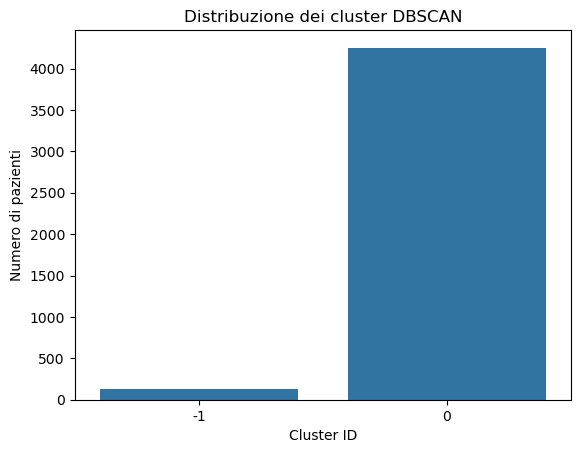

In [40]:
# Aggiungi i cluster assegnati al DataFrame
profile_df['cluster'] = dbscan.labels_

# Ora puoi creare il grafico
sns.countplot(x='cluster', data=profile_df)
plt.title("Distribuzione dei cluster DBSCAN")
plt.xlabel("Cluster ID")
plt.ylabel("Numero di pazienti")
plt.show()

# Analisi Approfondita dei Cluster

Analizziamo i cluster creati con DBSCAN per comprendere le caratteristiche dei diversi gruppi di pazienti.

In [41]:
# 1. Statistiche generali sui cluster
print("=" * 60)
print("STATISTICHE GENERALI SUI CLUSTER")
print("=" * 60)

# Conta i pazienti per cluster
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print(f"\nNumero totale di pazienti: {len(profile_df)}")
print(f"Numero di cluster : {len(cluster_counts)-1}")
print("\nDistribuzione pazienti per cluster:")
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(profile_df)) * 100
    cluster_name = "Noise" if cluster_id == -1 else f"Cluster {cluster_id}"
    print(f"  {cluster_name}: {count} pazienti ({percentage:.2f}%)")



STATISTICHE GENERALI SUI CLUSTER

Numero totale di pazienti: 4384
Numero di cluster : 1

Distribuzione pazienti per cluster:
  Noise: 133 pazienti (3.03%)
  Cluster 0: 4251 pazienti (96.97%)


### da togliere

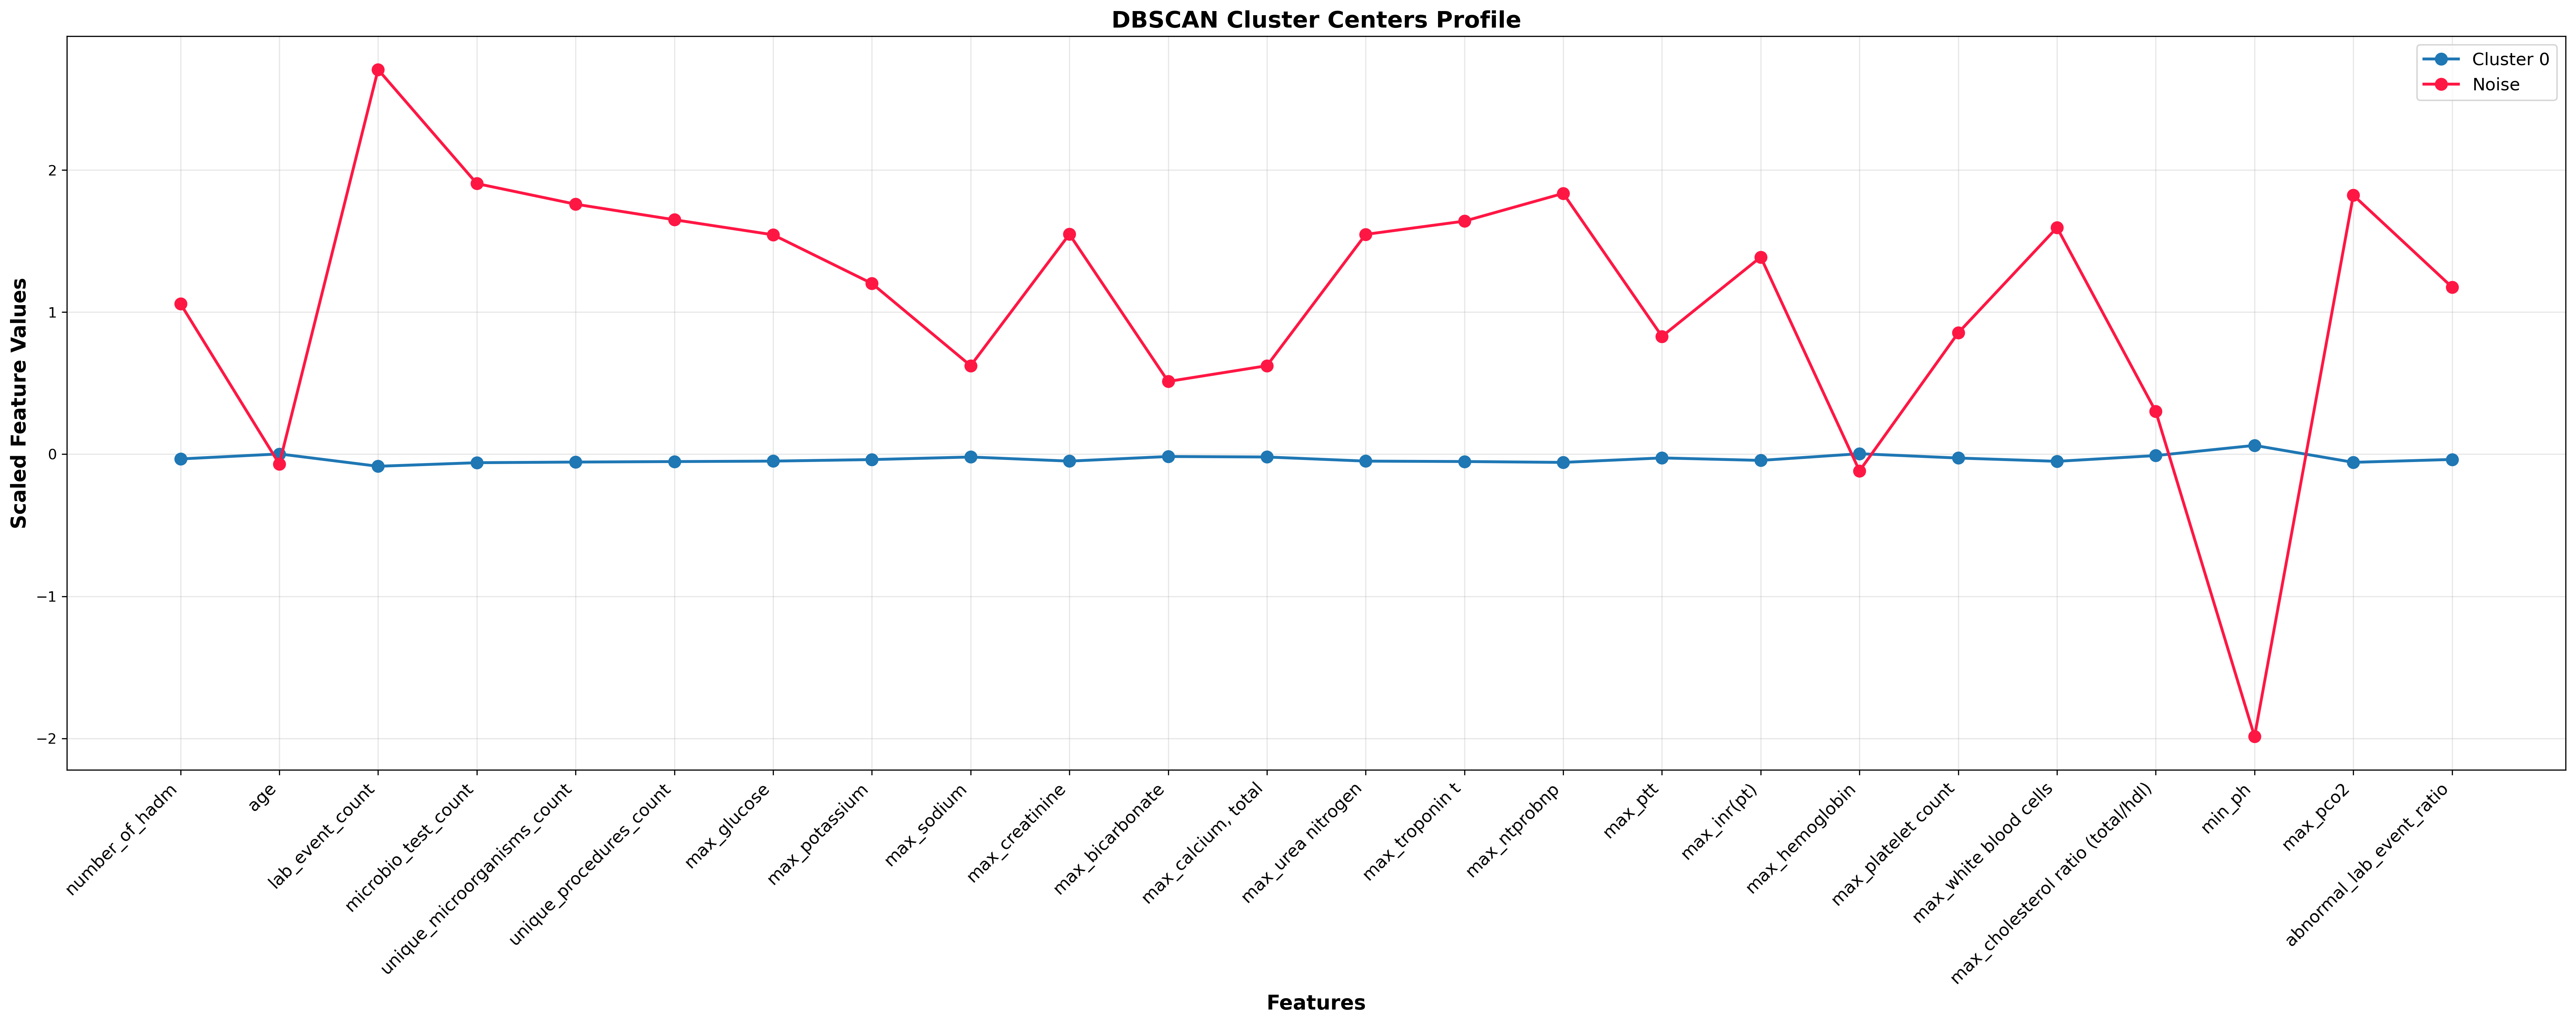


Numero di cluster trovati: 1
Noise points: 133


In [42]:
# Calcola i centri dei cluster DBSCAN
cluster_labels = dbscan.labels_

# Ottieni cluster univoci (escludendo noise -1)
unique_clusters = np.unique(cluster_labels)
unique_clusters = unique_clusters[unique_clusters != -1]  # Rimuovi noise

# Usa i nomi delle colonne numeriche
feature_names = numeric_cols

# Calcola i centri per ogni cluster (media delle features)
centers = []
cluster_ids = []
for cluster_id in unique_clusters:
    cluster_mask = cluster_labels == cluster_id
    cluster_center = X[cluster_mask].mean(axis=0)
    centers.append(cluster_center)
    cluster_ids.append(cluster_id)

# Calcola anche il centro del noise se presente
if -1 in cluster_labels:
    noise_mask = cluster_labels == -1
    noise_center = X[noise_mask].mean(axis=0)
    centers.append(noise_center)
    cluster_ids.append(-1)

centers = np.array(centers)

# Plot dei centri dei cluster
plt.figure(figsize=(25, 10), dpi=300)
for i, cluster_id in enumerate(cluster_ids):
    label = 'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
    color = '#FF1744' if cluster_id == -1 else None
    plt.plot(centers[i], marker='o', label=label, linewidth=2, markersize=8, color=color)

plt.tick_params(axis='both', which='major', labelsize=10)
plt.xticks(range(len(feature_names)), feature_names, fontsize=12, rotation=45, ha='right')
plt.xlabel('Features', fontsize=14, fontweight='bold')
plt.ylabel('Scaled Feature Values', fontsize=14, fontweight='bold')
plt.title('DBSCAN Cluster Centers Profile', fontsize=16, fontweight='bold')
plt.legend(fontsize=12, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nNumero di cluster trovati: {len(unique_clusters)}")
print(f"Noise points: {np.sum(cluster_labels == -1)}")


## Heatmap - Confronto Visivo tra Cluster

La heatmap mostra i **valori medi** di ogni feature numerica per ciascun cluster:
- **Colori caldi (rosso)**: valori alti
- **Colori freddi (blu)**: valori bassi
- **Righe**: features 
- **Colonne**: cluster

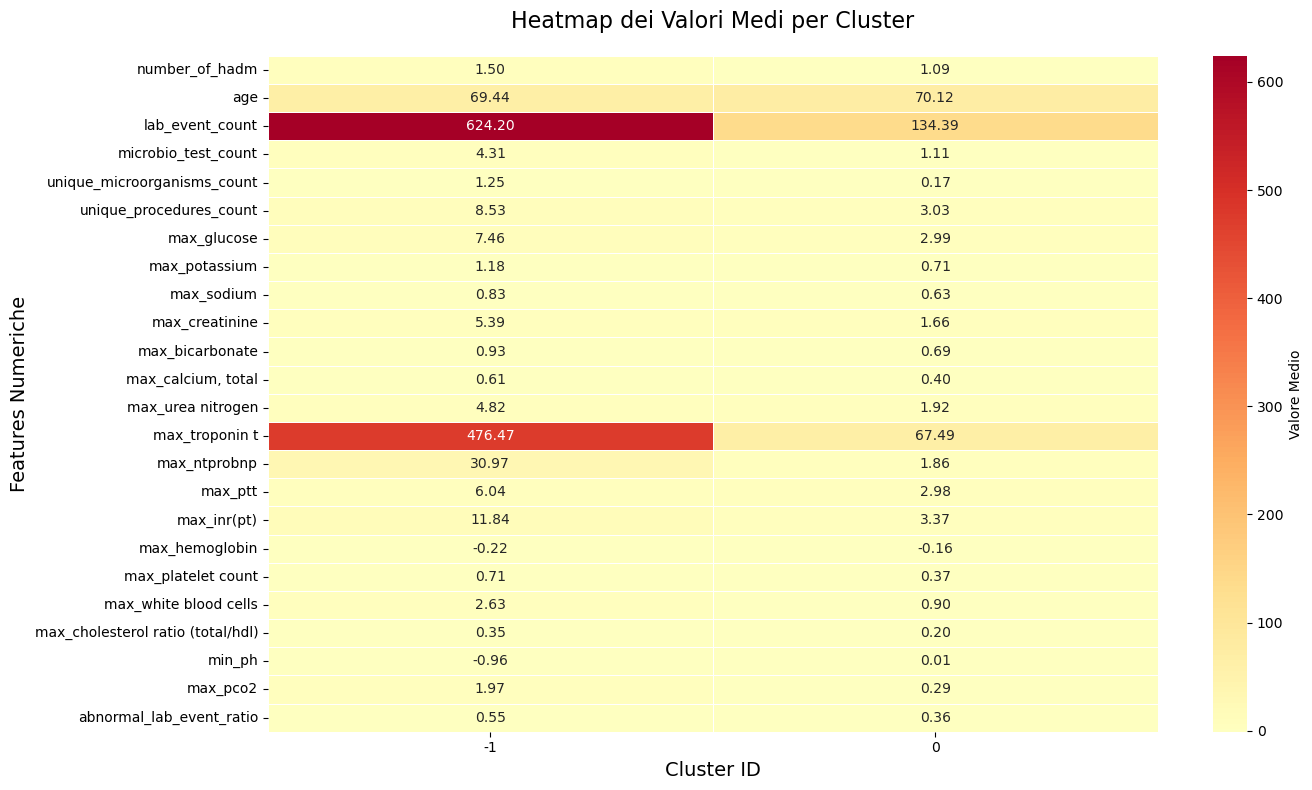

In [43]:
# Calcola le medie per cluster (escludendo subject_id e cluster)
numeric_cols_analysis = [col for col in numeric_cols if col not in ['subject_id', 'cluster']]
cluster_means = profile_df.groupby('cluster')[numeric_cols_analysis].mean()

# Crea la heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(cluster_means.T, annot=True, fmt='.2f', cmap='RdYlBu_r', 
            cbar_kws={'label': 'Valore Medio'}, linewidths=0.5, center=0.5)
plt.title('Heatmap dei Valori Medi per Cluster', fontsize=16, pad=20)
plt.xlabel('Cluster ID', fontsize=14)
plt.ylabel('Features Numeriche', fontsize=14)
plt.tight_layout()
plt.show()

The DBScan analysis identified a cohesive group comprising the majority of the cohort , representing the standard clinical profile, and Atypical Profiles

## Come Interpretare l'Heatmap

### Lettura Base
- **Ogni colonna** rappresenta un cluster diverso (es: -1 = noise, 0 = cluster 1, ecc.)
- **Ogni riga** rappresenta una feature numerica (età, troponina, lab_event_count, ecc.)
- **I numeri** nelle celle mostrano il valore medio di quella feature in quel cluster
- **I colori** aiutano la visualizzazione:
  - 🔴 **Rosso/Arancione**: valori alti rispetto agli altri cluster
  - 🔵 **Blu**: valori bassi rispetto agli altri cluster
  - ⚪ **Bianco/Giallo**: valori medi

### Come Confrontare i Cluster

1. **Confronto orizzontale** (lungo una riga):
   - Guarda una singola feature attraverso tutti i cluster
   -se una feature e rossa in un cluster e gialla negli altri, vuol dire che quel cluster ha valori critici
2. **Confronto verticale** (lungo una colonna):
   - Guarda il profilo completo di un singolo cluster
   - Esempio: se una colonna ha molte righe rosse, quel cluster ha pazienti con valori generalmente elevati

3. **Pattern distintivi**:
   - **Cluster simili**: avranno pattern di colori simili
   - **Cluster distinti**: avranno pattern molto diversi
   - **Features discriminanti**: righe con forte contrasto di colore tra cluster

### Esempio di Interpretazione Clinica

Si nota  che il **cluster del noise** (-1) ha:
- `max_troponin t` **alto** (rosso) → danno cardiaco elevato
- `max_ntprobnp` **alto** (rosso) → insufficienza cardiaca grave  
- `lab_event_count` **alto** (rosso) → molte analisi = pazienti complessi


**Conclusione**: Il noise potrebbe rappresentare **pazienti critici ad alto rischio** che non rientrano nei pattern standard.

In [44]:
#save the column cluster in  the profile
labels = dbscan.labels_
profile_df['cluster'] = labels
profile_df


,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio,cluster
0,10000980,1,0,1,0,0,0,0,0,0,...,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284,0
1,10002013,1,0,0,0,0,0,0,0,0,...,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000,0
2,10002155,1,0,0,0,0,0,0,0,0,...,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760,0
3,10004457,0,0,0,1,0,0,0,0,0,...,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333,0
4,10007058,1,0,0,0,0,0,0,0,0,...,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0


In [45]:
#percentage of each desease in each cluster
disease_cols = ['ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
disease_summary = profile_df.groupby('cluster')[disease_cols].mean() * 100  
disease_summary

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,
-1,48.872180,7.518797,41.353383,5.263158,0.751880,2.255639,0.000000,0.000000,9.774436
0,32.110092,14.584804,29.169607,6.139732,1.129146,5.339920,0.893907,0.047048,15.149377


### da togliere

In [46]:
#  valori della troponina in ogni cluster
troponin_summary = profile_df.groupby('cluster')['max_troponin t'].describe()
troponin_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,133.0,476.466165,784.234278,0.0,7.0,60.0,597.0,4130.0
0,4251.0,67.487415,190.052368,0.0,0.0,2.0,33.0,2445.0


In [47]:
#valori del nt-proBNP in ogni cluster
nt_summary = profile_df.groupby('cluster')['max_ntprobnp'].describe()
nt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,133.0,30.969554,70.505996,0.0,0.0,0.0,17.897436,407.881720
0,4251.0,1.860076,7.992711,0.0,0.0,0.0,0.000000,111.440678


In [48]:
#valore del inr_ptt in ogni cluster
pt_summary = profile_df.groupby('cluster')['max_inr(pt)'].describe()
pt_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,133.0,11.838346,17.318818,0.0,2.0,5.5,15.0,109.5
0,4251.0,3.365737,4.967473,-0.5,0.5,1.5,3.5,43.0


In [49]:
# lab events count  per cluster
lab_events_summary = profile_df.groupby('cluster')['lab_event_count'].describe()
lab_events_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,133.0,624.195489,529.278833,20.0,256.0,445.0,824.0,2851.0
0,4251.0,134.392614,125.616651,0.0,54.0,92.0,176.0,1045.0


In [50]:
#distribution of age in each cluster
age_summary = profile_df.groupby('cluster')['age'].describe()
age_summary

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
-1,133.0,69.443609,8.858666,25.0,69.0,69.0,75.0,89.0
0,4251.0,70.115267,9.455301,18.0,66.0,69.0,75.0,95.0


## Visualizzazioni Avanzate dei Cluster

Creiamo grafici più dettagliati per distinguere meglio i cluster.

### 1. Boxplot - Confronto Features Chiave tra Cluster

I boxplot mostrano la distribuzione completa (mediana, quartili, outlier) di ogni feature per cluster.

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\3354104449.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\3354104449.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\3354104449.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx],

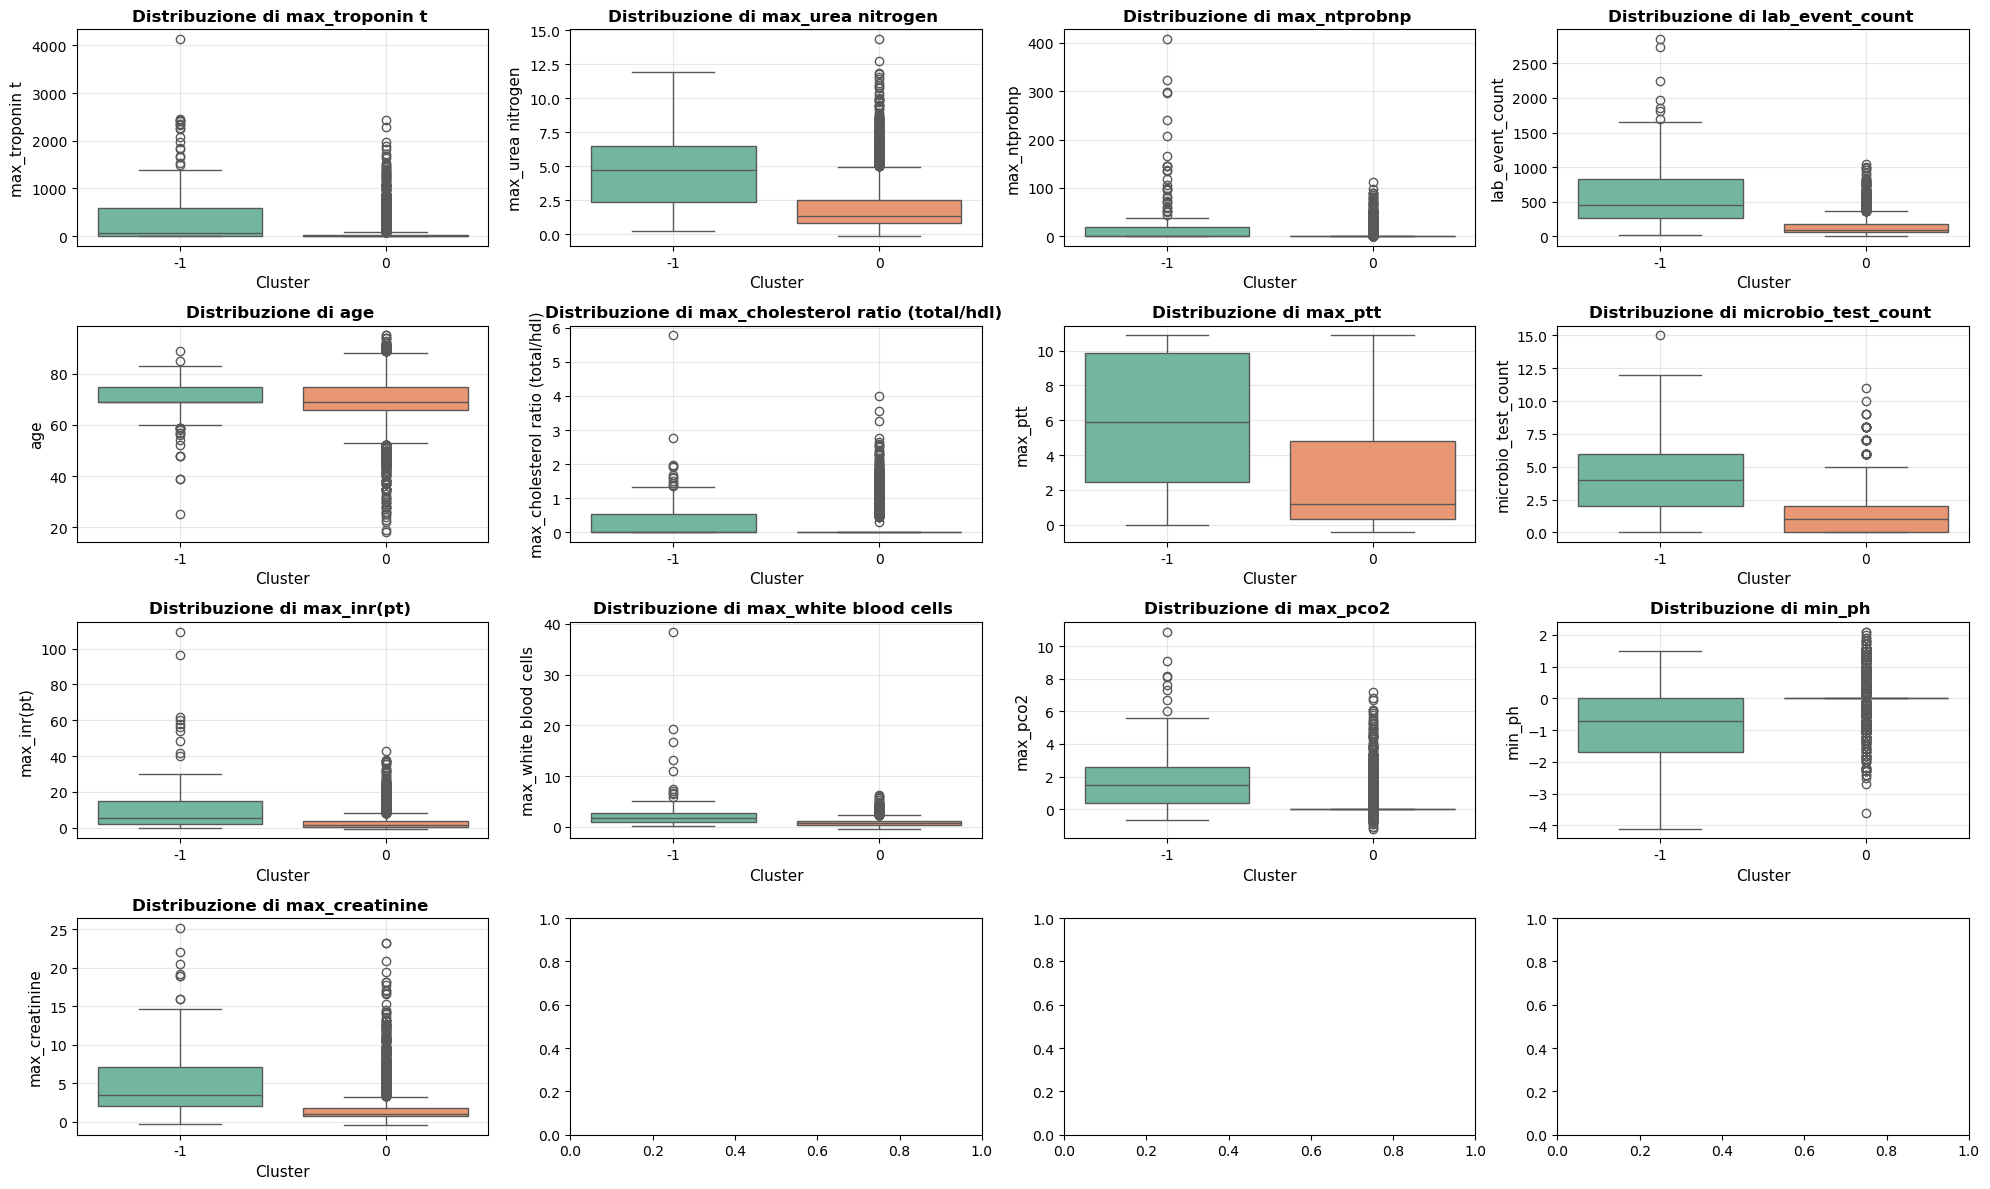

In [51]:
# Seleziona features chiave da visualizzare
key_features = ['max_troponin t','max_urea nitrogen','max_ntprobnp', 'lab_event_count', 'age','max_cholesterol ratio (total/hdl)',
                'max_ptt','microbio_test_count','max_inr(pt)','max_white blood cells','max_pco2','min_ph','max_creatinine']

fig, axes = plt.subplots(4, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribuzione di {feature} ', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\2264759127.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\2264759127.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_16956\2264759127.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx],

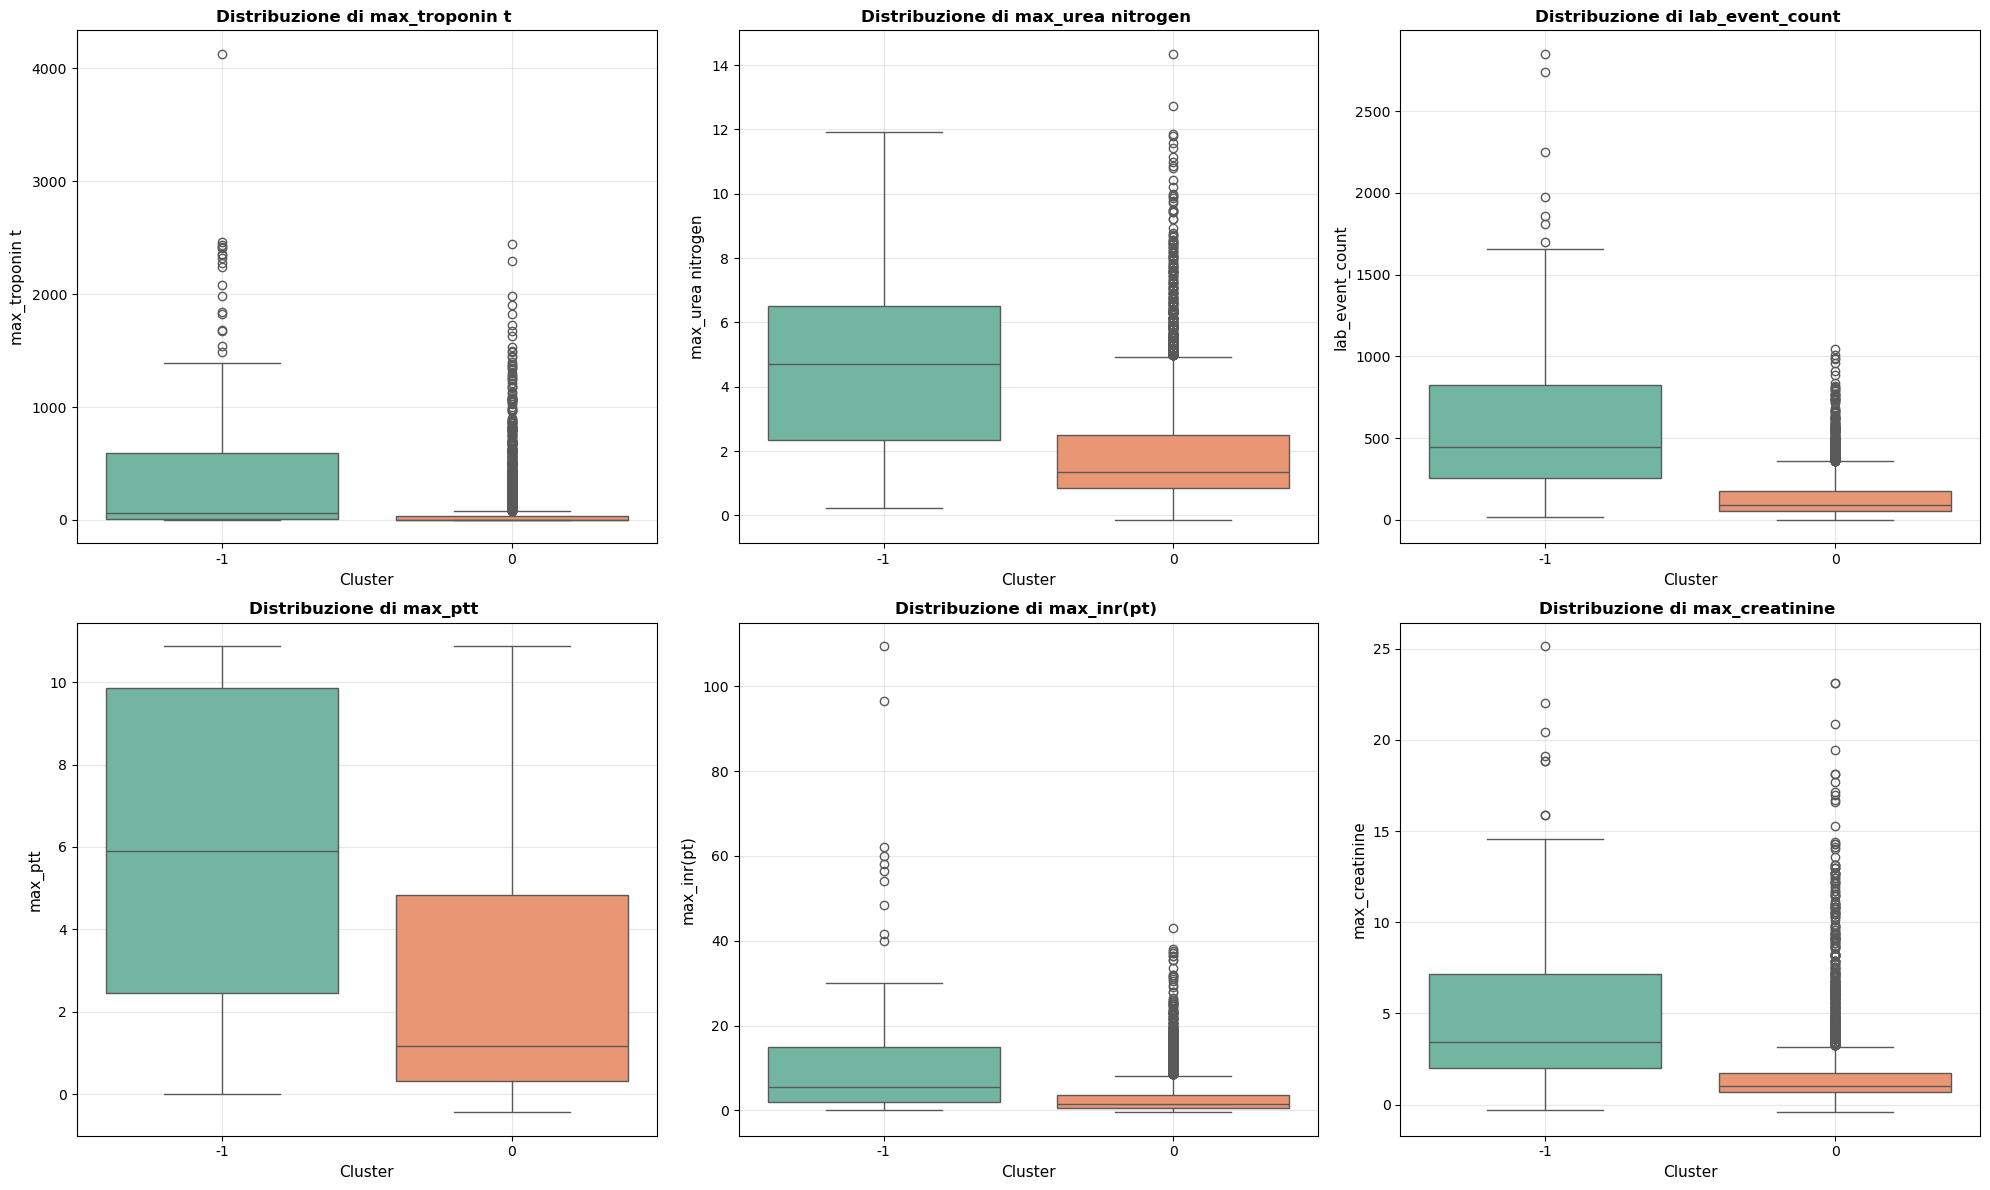

In [55]:
# Seleziona features chiave da visualizzare
key_features = ['max_troponin t','max_urea nitrogen', 'lab_event_count', 
                'max_ptt','max_inr(pt)','max_creatinine']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribuzione di {feature} ', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The boxplots display the distributions of selected key clinical variables for DBSCAN core points and peripheral observations. Peripheral observations are not interpreted as a distinct subgroup but rather as extreme cases within a continuous population. In this context, the boxplots primarily highlight increased dispersion and the presence of extreme values among peripheral points, rather than systematic differences between groups. In particular, peripheral cases exhibit higher monitoring intensity, elevated cardiac biomarkers, and more pronounced alterations in acid–base balance and coagulation parameters, consistent with severe and heterogeneous clinical presentations. In contrast, age distributions largely overlap, indicating that peripheral status is driven by clinical complexity rather than demographic factors.

### 6. Scatter Plot - Separazione dei Cluster per Coppie di Features



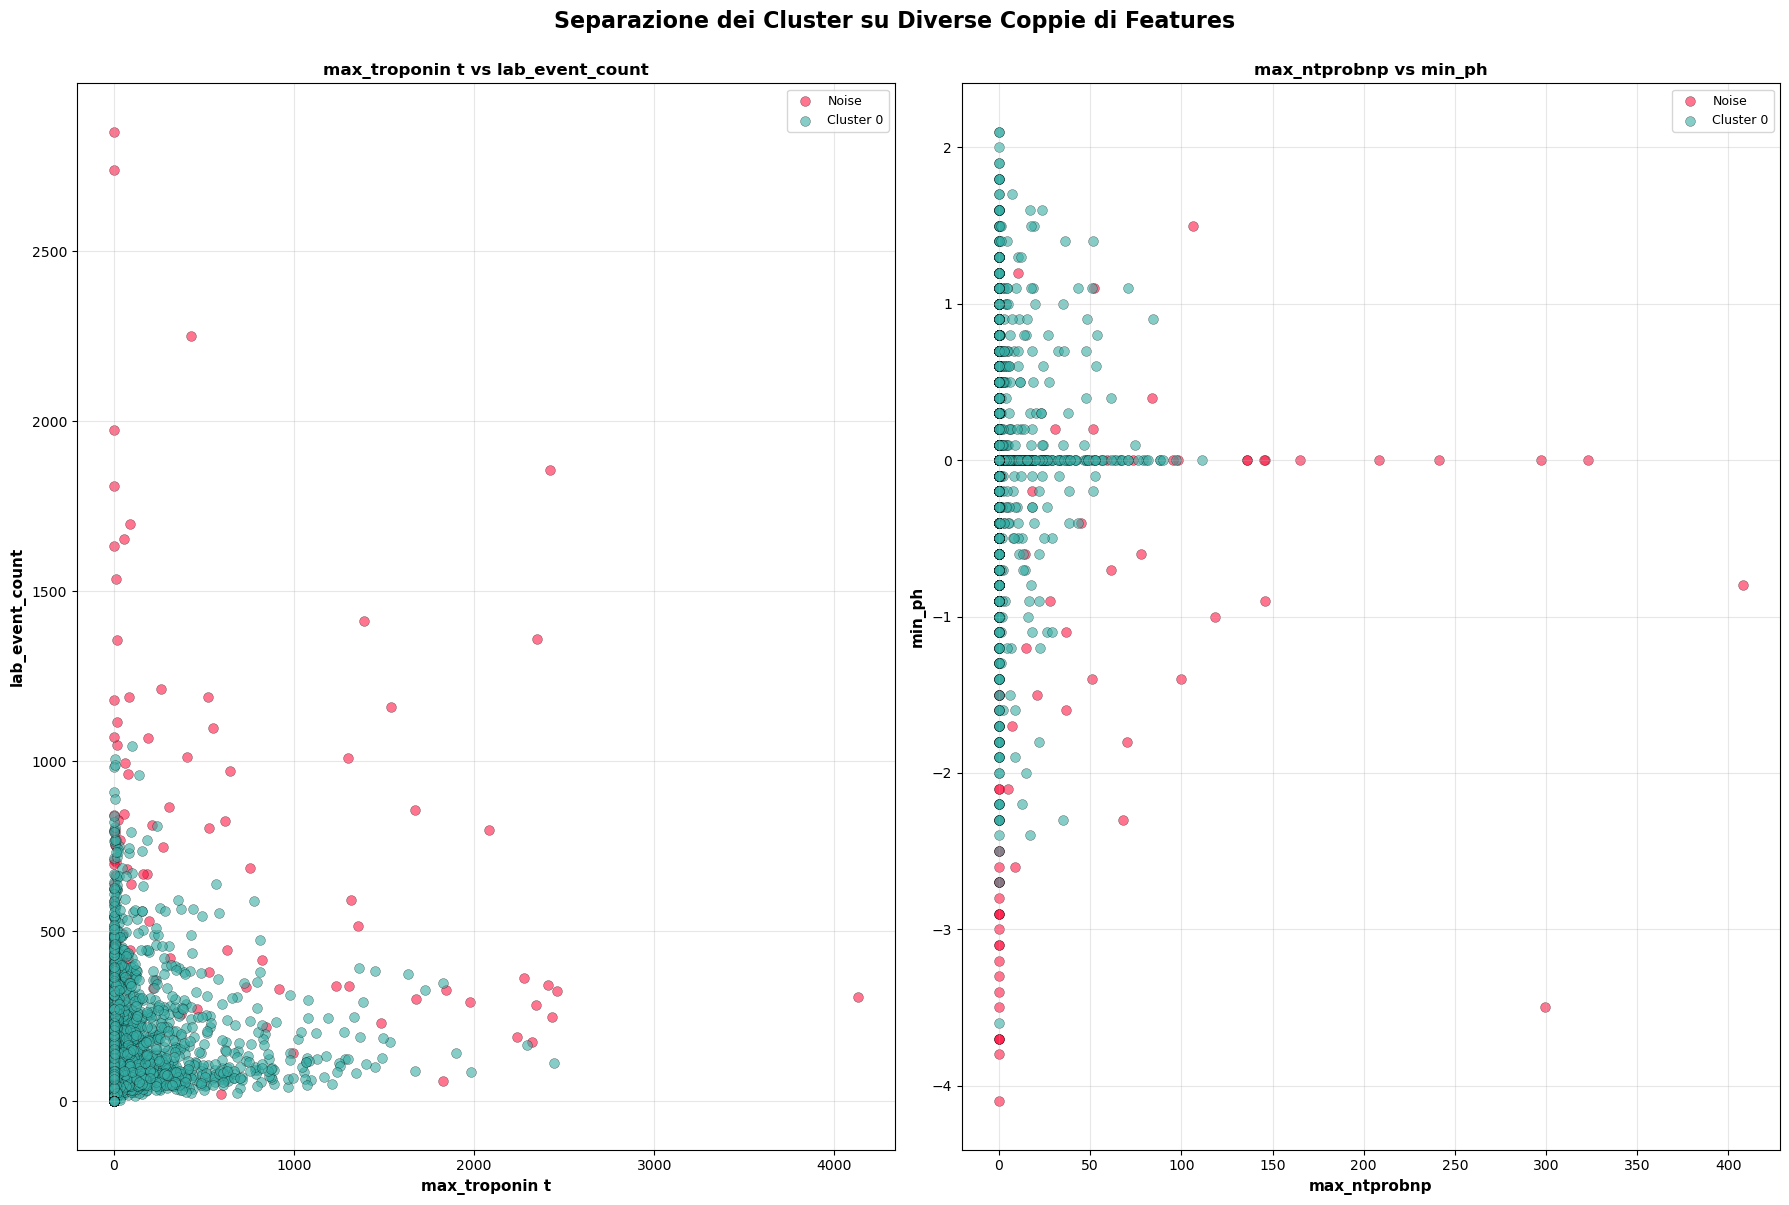

In [53]:
# Scatter plot con diverse combinazioni di features
fig, axes = plt.subplots(1,2 , figsize=(18, 12))
axes = axes.flatten()

# Definisci le coppie di features da visualizzare
feature_pairs = [

    ('max_troponin t', 'lab_event_count'),
    ('max_ntprobnp', 'min_ph'),
    
]

# Mappa colori per tutti i cluster - palette bella e diversificata
unique_clusters = sorted(profile_df['cluster'].unique())
palette = sns.color_palette("husl", n_colors=len(unique_clusters))
colors_map = {
    cluster_id: '#FF1744' if cluster_id == -1 else palette[idx % len(palette)]
    for idx, cluster_id in enumerate(unique_clusters)
}

for idx, (feat_x, feat_y) in enumerate(feature_pairs):
    for cluster_id in unique_clusters:
        cluster_data = profile_df[profile_df['cluster'] == cluster_id]
        label = 'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
        color = colors_map.get(cluster_id, 'gray')
        
        axes[idx].scatter(
            cluster_data[feat_x],
            cluster_data[feat_y],
            label=label,
            alpha=0.6,
            s=50,
            color=color,
            edgecolors='k',
            linewidth=0.3
        )
    
    axes[idx].set_xlabel(feat_x, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(feat_y, fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{feat_x} vs {feat_y}', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=9, loc='best')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Separazione dei Cluster su Diverse Coppie di Features', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

Scattered noise points indicate atypical patients who do not conform to the predominant clinical patterns observed in the cohort.

### dat togliere

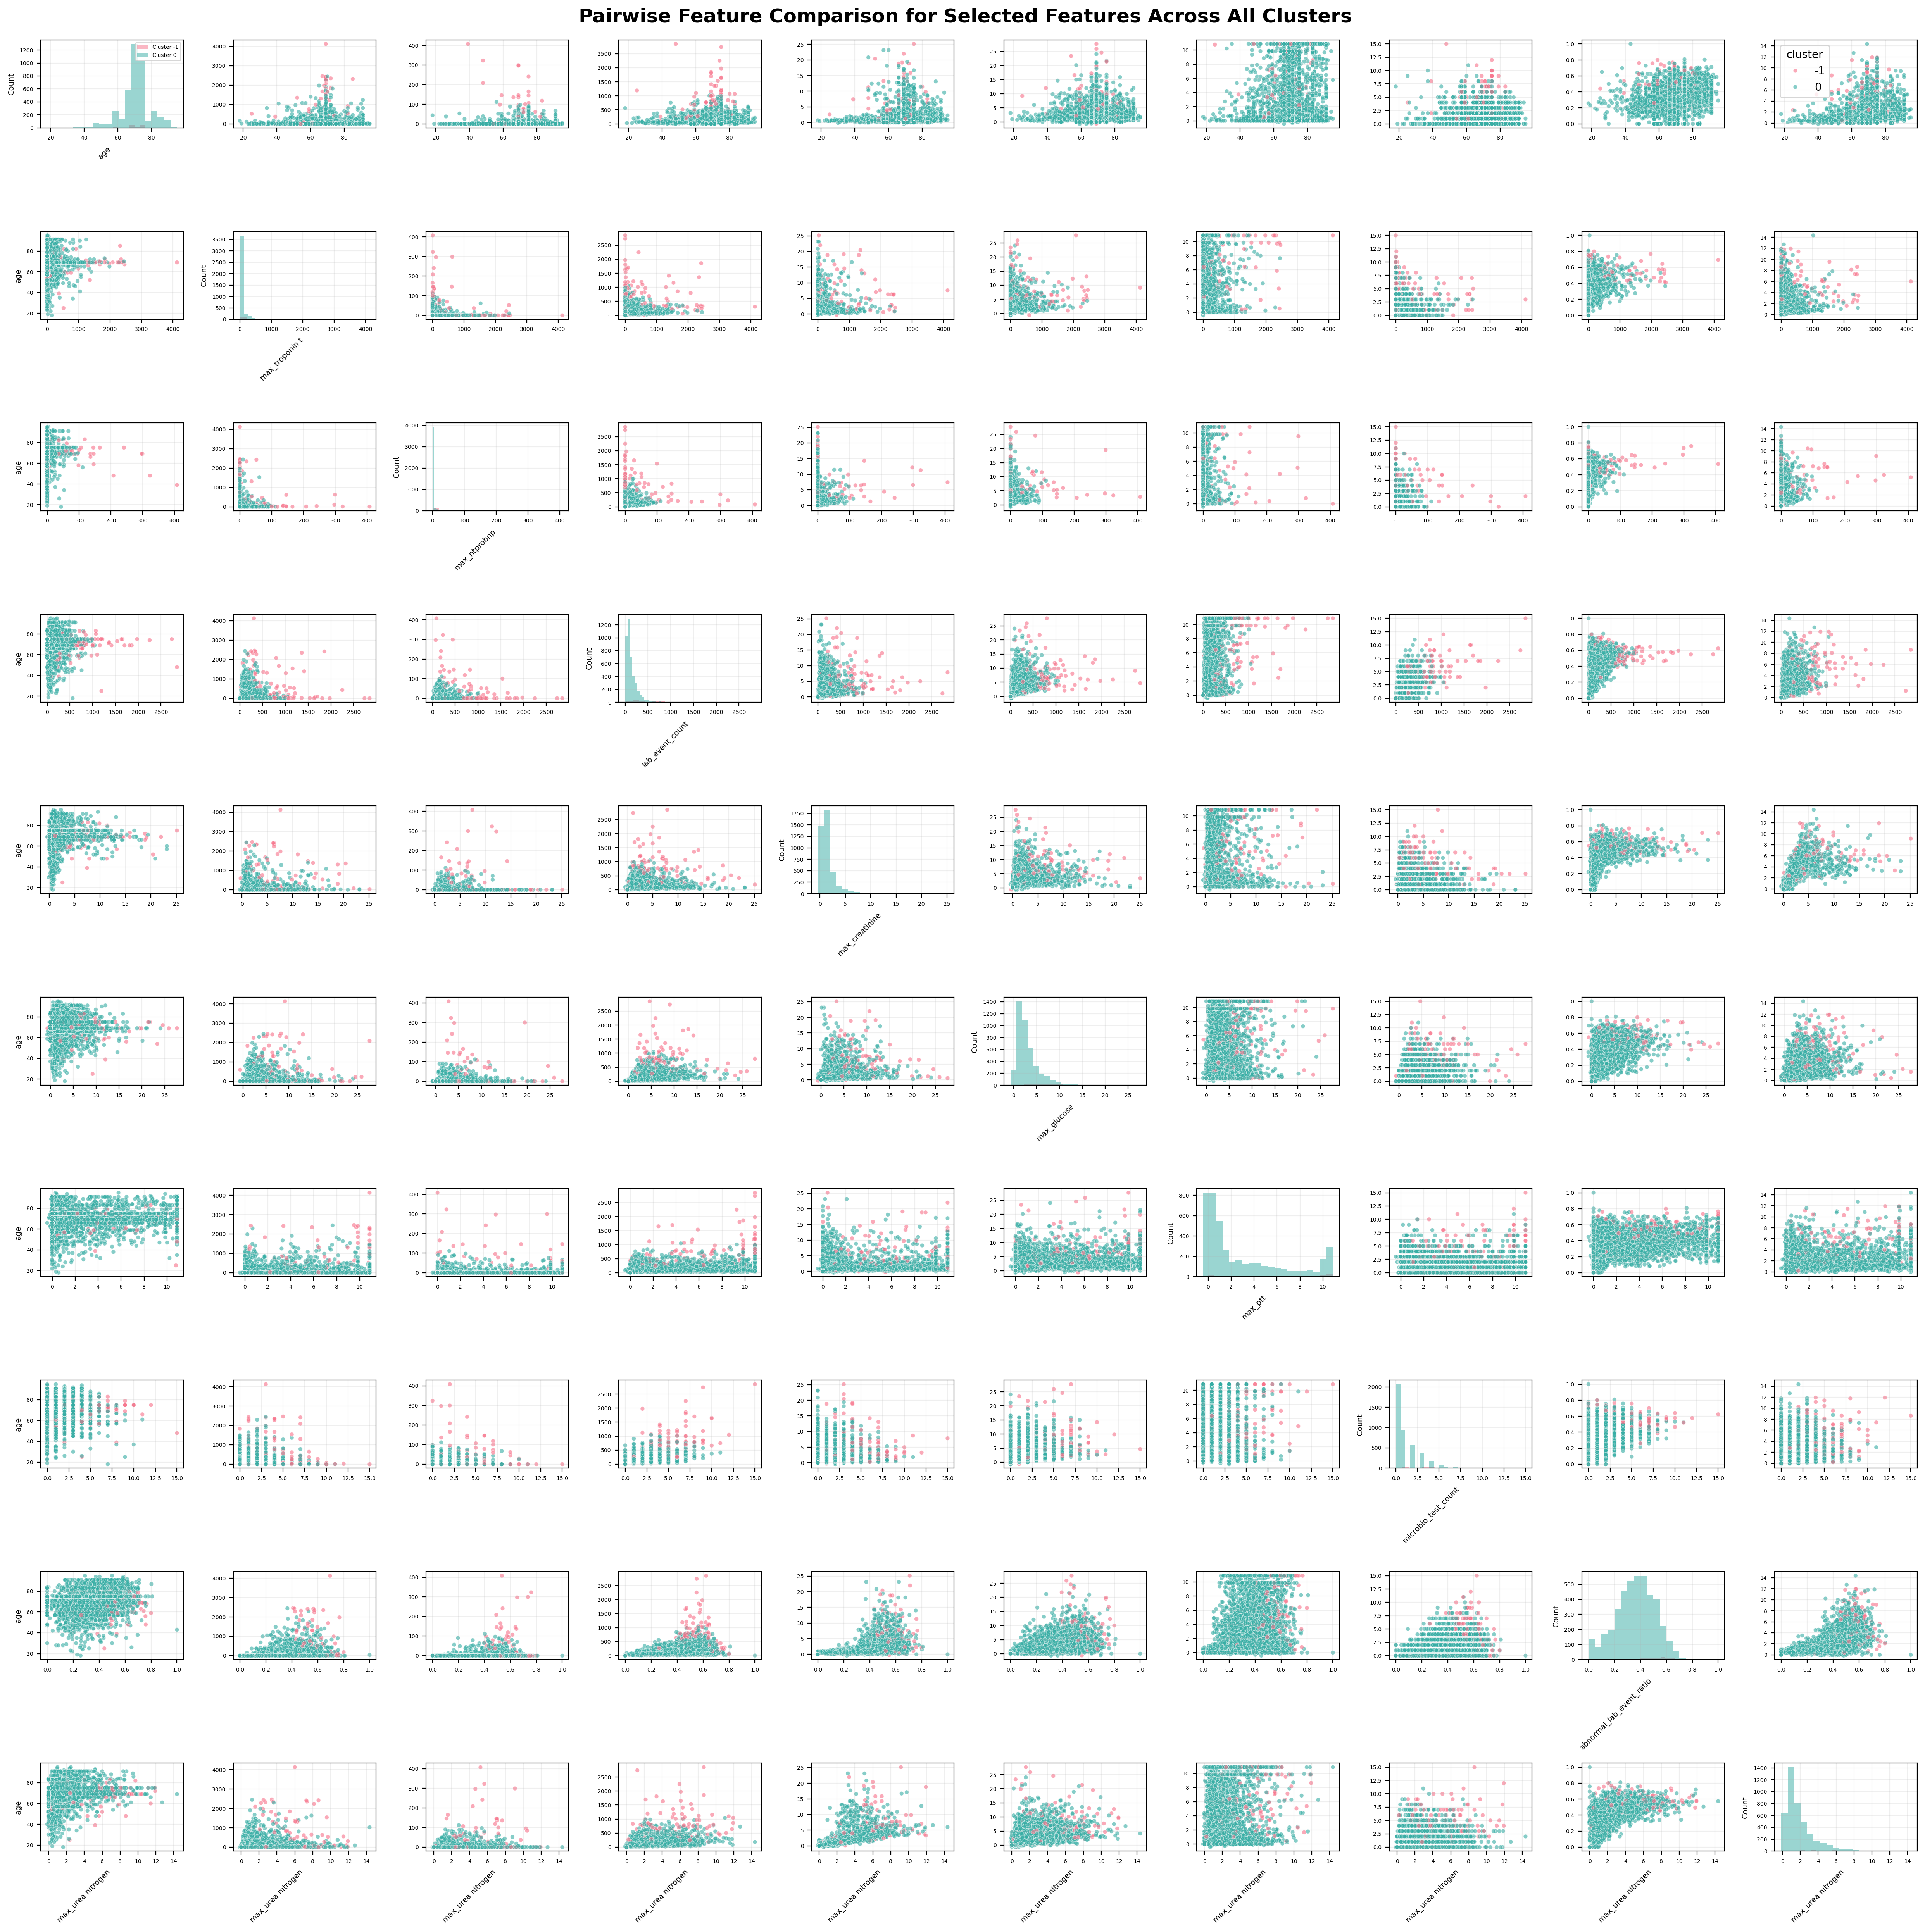

In [54]:
# Seleziona coppie specifiche di feature da visualizzare
selected_features = [
    'age', 'max_troponin t', 'max_ntprobnp', 'lab_event_count', 
    'max_creatinine', 'max_glucose', 'max_ptt', 'microbio_test_count',
    'abnormal_lab_event_ratio', 'max_urea nitrogen'
]

n = len(selected_features)
lab = profile_df['cluster']

fig, axs = plt.subplots(n, n, figsize=(25, 25), dpi=200)

# Mappa colori per cluster
unique_clusters = sorted(profile_df['cluster'].unique())
palette_grid = sns.color_palette("husl", n_colors=len(unique_clusters))
colors_map_grid = {cluster_id: palette_grid[idx] for idx, cluster_id in enumerate(unique_clusters)}

for i in np.arange(0, n):
    x_feature = selected_features[i]
    for j in np.arange(0, n):
        y_feature = selected_features[j]
        
        if i == j:
            # Sulla diagonale, mostra la distribuzione della singola feature
            for cluster_id in unique_clusters:
                cluster_data = profile_df[profile_df['cluster'] == cluster_id]
                axs[i, j].hist(cluster_data[x_feature], alpha=0.5, 
                              label=f'Cluster {cluster_id}',
                              color=colors_map_grid[cluster_id], bins=20)
            axs[i, j].set_xlabel(x_feature, fontsize=7, rotation=45, ha='right')
            axs[i, j].set_ylabel('Count', fontsize=7)
            if i == 0:
                axs[i, j].legend(fontsize=5, loc='upper right')
        else:
            # Fuori dalla diagonale, mostra scatter plot
            sns.scatterplot(x=x_feature, y=y_feature, data=profile_df, 
                          hue='cluster', ax=axs[i, j], alpha=0.6, s=15,
                          palette=colors_map_grid, legend=(i == 0 and j == n-1))
            axs[i, j].set_xlabel(x_feature if i == n-1 else '', fontsize=7, rotation=45, ha='right')
            axs[i, j].set_ylabel(y_feature if j == 0 else '', fontsize=7)
        
        axs[i, j].tick_params(labelsize=5)
        axs[i, j].grid(True, alpha=0.2)

plt.suptitle('Pairwise Feature Comparison for Selected Features Across All Clusters', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

DBSCAN identified a single high-density global core, indicating a high degree of homogeneity across the majority of the cohort, with approximately 3% of patients classified as isolated outliers (noise). Rather than revealing distinct subgroups, the algorithm highlighted atypical, high-variance cases that deviate from the predominant clinical patterns, suggesting the presence of patients requiring more individualized clinical attention.